# NN_L8_yc_density

**Lecture 8 of Neural Networks and Deep Learning (NN). Density of the euro-area 10-year AAA yield: real daily curves against curves generated by a diffusion model (DDPM), a multivariate Gaussian and a VAE (5,000 samples each, seed 1).**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_yc_density/NN_L8_yc_density.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Regimes of euro rates: share of negative 10-year yields, minimum and maximum.

days with a negative 10-year yield (%) = 13.8   [yc.pct_neg10_real]
minimum 10-year yield (%) = -0.82   [yc.y10_min]
maximum 10-year yield (%) = 4.78   [yc.y10_max]


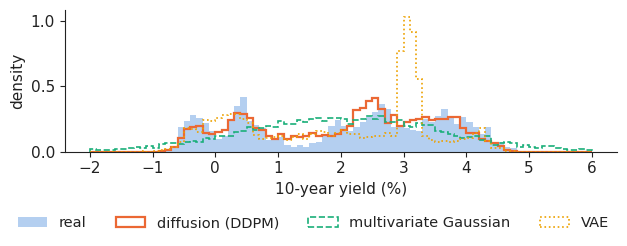

In [3]:
yc = pd.read_csv(DATA + 'ecb_yield_curve_daily.csv', parse_dates=['date']).set_index('date')
end = (yc.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
MAT = ['y_3M', 'y_6M', 'y_1Y', 'y_2Y', 'y_3Y', 'y_5Y', 'y_7Y', 'y_10Y', 'y_15Y', 'y_20Y', 'y_30Y']
yc = yc.loc[:end].dropna()
Y = yc[MAT].values
y10, slope = Y[:, 7], Y[:, 7] - Y[:, 0]
g = pd.read_csv(REPO + 'lectures/L8/results/' + 'yc_generated_y10.csv')
show('yc.pct_neg10_real', 'days with a negative 10-year yield (%)', round(100 * float(np.mean(y10 < 0)), 1))
show('yc.y10_min', 'minimum 10-year yield (%)', round(float(y10.min()), 2))
show('yc.y10_max', 'maximum 10-year yield (%)', round(float(y10.max()), 2))
b = np.linspace(-2, 6, 81)
fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.hist(y10, bins=b, density=True, histtype='stepfilled', alpha=0.35, color=PAL['data'], label='real')
ax.hist(g.ddpm, bins=b, density=True, histtype='step', lw=1.6, color=PAL['model'], label='diffusion (DDPM)')
ax.hist(g.gauss, bins=b, density=True, histtype='step', lw=1.2, ls='--', color=PAL['benchmark'], label='multivariate Gaussian')
ax.hist(g.vae, bins=b, density=True, histtype='step', lw=1.2, ls=':', color=PAL['alt'], label='VAE')
ax.set_xlabel('10-year yield (%)'); ax.set_ylabel('density')
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('yc_density.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()